# Machine Learning Laboratory
## Experiment 06
### Implementation of Classification Algorithms
Algorithms used: Logistic Regression, K-Nearest Neighbours (KNN), and Gaussian Naive Bayes.

#### 1 Aim
To perform data inspection, data cleaning, preprocessing, feature scaling, and binary classification on the Pima Indians Diabetes dataset using Logistic Regression, KNN, and Gaussian Naive Bayes, and compare their performance using accuracy.

### Step 1: Load the Raw CSV

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score

In [2]:
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

data = pd.read_csv(
    "pima-indians-diabetes.data.csv",
    header=None,
    names=columns
)

### Step 2: Inspect the Data

In [3]:
print(data.head())
print(data.tail())
print(data.shape)
print(data.columns)
print(data.dtypes)
print(data.describe())

   Pregnancies  Glucose  BloodPressure  ...  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72  ...                     0.627   50        1
1            1       85             66  ...                     0.351   31        0
2            8      183             64  ...                     0.672   32        1
3            1       89             66  ...                     0.167   21        0
4            0      137             40  ...                     2.288   33        1

[5 rows x 9 columns]
     Pregnancies  Glucose  ...  Age  Outcome
763           10      101  ...   63        0
764            2      122  ...   27        0
765            5      121  ...   30        0
766            1      126  ...   47        1
767            1       93  ...   23        0

[5 rows x 9 columns]
(768, 9)
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='str')
Pregnancies    

### Step 3: Check Duplicate Records

In [4]:
print("Number of duplicate rows:",
      data.duplicated().sum())

Number of duplicate rows: 0


### Step 4: Remove Duplicate Records

In [5]:
data = data.drop_duplicates()

### Step 5: Identify Invalid Zero Values
First count zeros in every column:

In [6]:
print((data == 0).sum())

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


### Step 6: Convert Invalid Zeros to NaN

In [7]:
invalid_zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

data[invalid_zero_columns] = data[
    invalid_zero_columns
].replace(0, np.nan)

### Step 7: Inspect Missing Values

In [8]:
print(data.isnull().sum())

missing_percentage = (
    data.isnull().sum() / len(data)
) * 100

print(missing_percentage)

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64
Pregnancies                  0.000000
Glucose                      0.651042
BloodPressure                4.557292
SkinThickness               29.557292
Insulin                     48.697917
BMI                          1.432292
DiabetesPedigreeFunction     0.000000
Age                          0.000000
Outcome                      0.000000
dtype: float64


### Step 8: Handle Missing Values
For this introductory experiment, use median imputation for the numerical measurement columns.

In [9]:
for column in invalid_zero_columns:
    data[column] = data[column].fillna(
        data[column].median()
    )

print(data.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


### Step 9: Verify Cleaning

In [10]:
print(data.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


### Step 10: Inspect Outliers

<ipython-input-1-21e84986c056>:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


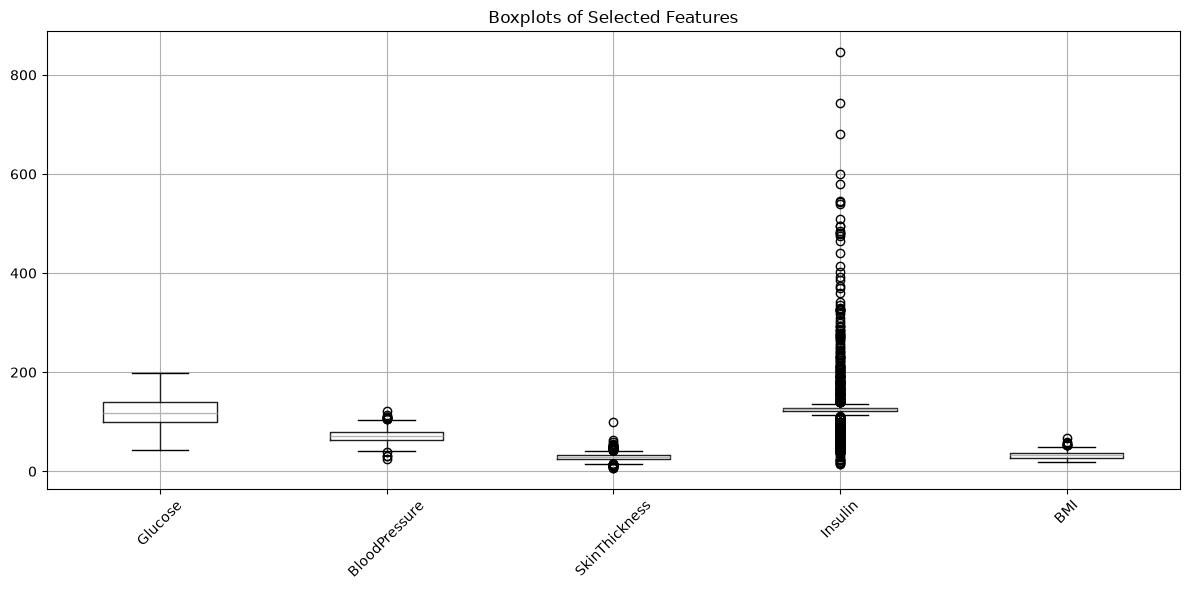

In [11]:
import matplotlib.pyplot as plt

data[invalid_zero_columns].boxplot(figsize=(12, 6))
plt.xticks(rotation=45)
plt.title("Boxplots of Selected Features")
plt.tight_layout()
plt.show()

### Step 11: Separate Features and Target
The target column is Outcome.

In [12]:
X = data.drop("Outcome", axis=1)
y = data["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


### Step 12: Train-Test Split

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


### Step 13: Feature Scaling

In [14]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 15: Logistic Regression

In [15]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(
    X_test_scaled
)

accuracy_lr = accuracy_score(
    y_test,
    y_pred_lr
)

print("Logistic Regression Accuracy:",
      accuracy_lr * 100, "%")

Logistic Regression Accuracy: 70.77922077922078 %


### Step 16: K-Nearest Neighbours
Use k = 5 initially.

In [16]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(
    X_test_scaled
)

accuracy_knn = accuracy_score(
    y_test,
    y_pred_knn
)

print("KNN Accuracy:",
      accuracy_knn * 100, "%")

KNN Accuracy: 75.32467532467533 %


### Step 17: Gaussian Naive Bayes
Because the input features are numerical, use Gaussian Naive Bayes.

In [17]:
nb_model = GaussianNB()

nb_model.fit(
    X_train_scaled,
    y_train
)

y_pred_nb = nb_model.predict(
    X_test_scaled
)

accuracy_nb = accuracy_score(
    y_test,
    y_pred_nb
)

print("Naive Bayes Accuracy:",
      accuracy_nb * 100, "%")

Naive Bayes Accuracy: 70.12987012987013 %


### Step 18: Compare the Classifiers

In [18]:
results = pd.DataFrame({
    "Algorithm": [
        "Logistic Regression",
        "KNN",
        "Naive Bayes"
    ],
    "Accuracy (%)": [
        accuracy_lr * 100,
        accuracy_knn * 100,
        accuracy_nb * 100
    ]
})

print(results)

             Algorithm  Accuracy (%)
0  Logistic Regression     70.779221
1                  KNN     75.324675
2          Naive Bayes     70.129870


### Step 19: Identify the Highest Accuracy

In [19]:
best_algorithm = results.loc[
    results["Accuracy (%)"].idxmax()
]

print("Best algorithm based on accuracy:")
print(best_algorithm)

Best algorithm based on accuracy:
Algorithm             KNN
Accuracy (%)    75.324675
Name: 1, dtype: object
